1. Downloaded 2D Image Matrix (5x5):
 [[103 106 110 117 113]
 [161 167 173 184 179]
 [180 186 182 186 183]
 [175 181 176 181 176]
 [168 174 175 185 178]]


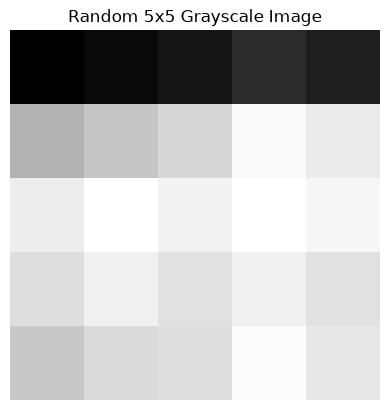


2. Convolution Output (Feature Map):
 [[-21. -28. -10.]
 [-15. -17.  -7.]
 [-10. -11.  -4.]]

3. ReLU Output:
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

4. Max Pooling Output (2x2):
 [[0. 0.]
 [0. 0.]]

5. Flattened Vector:
 [0. 0. 0. 0.]

6. Final Softmax Probabilities:
Cat:  33.33%
Dog:  33.33%
Bird: 33.33%


In [4]:
import numpy as np
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

# 1. Internet se Random Image uthana
url = "https://picsum.photos/50" # Random 50x50 image URL
response = requests.get(url)

# Image ko read karna, Grayscale (2D) mein convert karna aur 5x5 size mein resize karna
img = Image.open(BytesIO(response.content)).convert('L')
img_resized = img.resize((5, 5))
image = np.array(img_resized)

print("1. Downloaded 2D Image Matrix (5x5):\n", image)

# Image ko screen par show karna
plt.imshow(image, cmap='gray')
plt.title("Random 5x5 Grayscale Image")
plt.axis('off')
plt.show()

# 2. Convolution Layer (3x3 Kernel)
kernel = np.array([
    [1,  0, -1],
    [1,  0, -1],
    [1,  0, -1]
])

feature_map = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        # Image ke hisse ko kernel se multiply kar ke sum karna
        feature_map[i, j] = np.sum(image[i:i+3, j:j+3] * kernel)

print("\n2. Convolution Output (Feature Map):\n", feature_map)

# 3. ReLU Activation (Negative values ko 0 karna)
relu_output = np.maximum(0, feature_map)
print("\n3. ReLU Output:\n", relu_output)

# 4. Max Pooling Layer (2x2 Window)
pooled_output = np.zeros((2, 2))
for i in range(2):
    for j in range(2):
        pooled_output[i, j] = np.max(relu_output[i:i+2, j:j+2])

print("\n4. Max Pooling Output (2x2):\n", pooled_output)

# 5. Flattening (2D ko 1D Vector banانا)
flattened = pooled_output.flatten()
print("\n5. Flattened Vector:\n", flattened)

# 6. Fully Connected Layer & Softmax
weights_cat = np.array([0.3, 0.1, 0.2, 0.1])
weights_dog = np.array([0.1, 0.2, 0.1, 0.3])
weights_bird = np.array([0.0, 0.4, 0.1, 0.2])

logit_cat = np.dot(flattened, weights_cat)
logit_dog = np.dot(flattened, weights_dog)
logit_bird = np.dot(flattened, weights_bird)

logits = np.array([logit_cat, logit_dog, logit_bird])

# Calculation ko overflow se bachane ke liye safe logit technique
logits_safe = logits - np.max(logits)
exp_logits = np.exp(logits_safe)
softmax_probs = exp_logits / np.sum(exp_logits)

print("\n6. Final Softmax Probabilities:")
print(f"Cat:  {softmax_probs[0]*100:.2f}%")
print(f"Dog:  {softmax_probs[1]*100:.2f}%")
print(f"Bird: {softmax_probs[2]*100:.2f}%")